Notebook 6: Trend Analysis & Forecasting

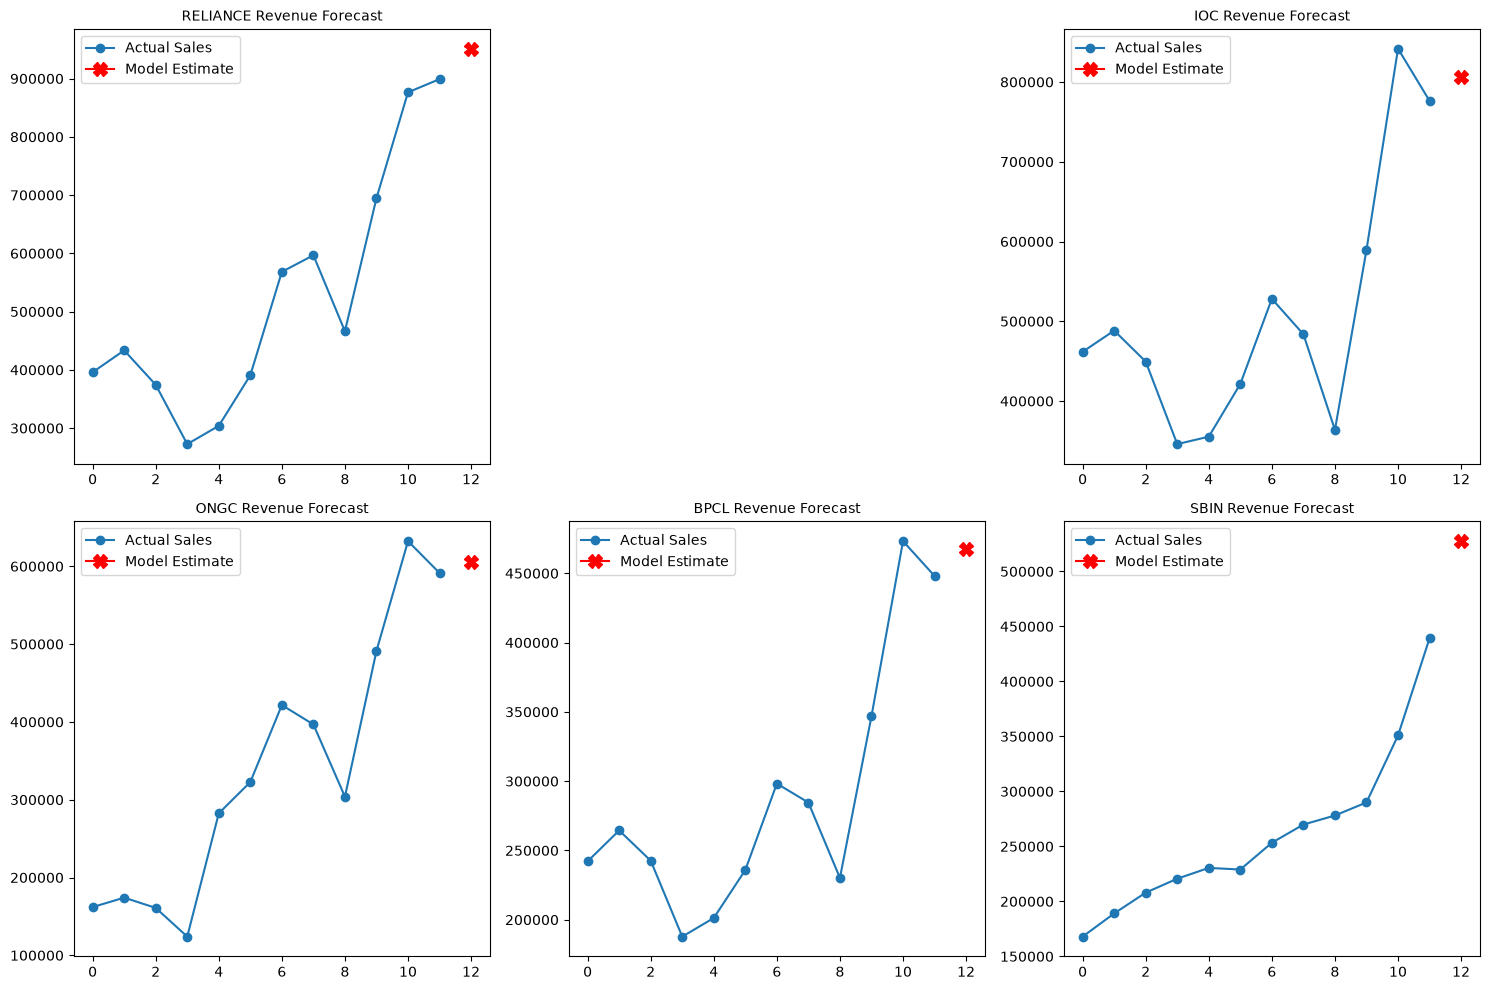

✅ Trend classifications and forecasts exported (Marked as Model Estimates, not Financial Advice).


In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import matplotlib.pyplot as plt

# 1. Load Data
pl = pd.read_csv('../data/clean/clean_profit_loss.csv')
pl = pl[pl['year_label'] != 'TTM'].sort_values(['symbol', 'year_id'])

trend_results = []
forecast_results = []

# 2. Linear Regression Trend Classification (Last 5 Years)
for symbol, group in pl.groupby('symbol'):
    recent = group.tail(5)['sales'].dropna()
    if len(recent) > 3:
        x = np.arange(len(recent))
        y = recent.values
        slope, _ = np.polyfit(x, y, 1)
        
        # Classify Trend
        if slope > (y.mean() * 0.05): trend = 'UP'
        elif slope < -(y.mean() * 0.05): trend = 'DOWN'
        else: trend = 'FLAT'
        
        trend_results.append({'symbol': symbol, 'revenue_trend': trend})

# 3. Holt-Winters Revenue Forecasting for Top 20 Companies
latest_year = pl['year_id'].max()
top_20_symbols = pl[pl['year_id'] == latest_year].nlargest(20, 'sales')['symbol'].tolist()

plt.figure(figsize=(15, 10))
for i, symbol in enumerate(top_20_symbols[:6]):  # Plotting top 6 for visibility
    ts_data = pl[pl['symbol'] == symbol]['sales'].values
    if len(ts_data) >= 8:
        # Fit Exponential Smoothing model
        model = ExponentialSmoothing(ts_data, trend='add', seasonal=None, initialization_method="estimated")
        fit_model = model.fit()
        forecast = fit_model.forecast(1)[0]
        
        forecast_results.append({'symbol': symbol, 'forecasted_revenue': forecast, 'fiscal_year': latest_year + 1})
        
        # Visualize
        plt.subplot(2, 3, i+1)
        plt.plot(range(len(ts_data)), ts_data, marker='o', label='Actual Sales')
        plt.plot(len(ts_data), forecast, marker='X', color='red', markersize=10, label='Model Estimate')
        plt.title(f"{symbol} Revenue Forecast", fontsize=10)
        plt.legend()

plt.tight_layout()
plt.show()

# 4. Export
pd.DataFrame(trend_results).to_csv('../data/revenue_trends.csv', index=False)
pd.DataFrame(forecast_results).to_csv('../data/revenue_forecasts.csv', index=False)
print("✅ Trend classifications and forecasts exported (Marked as Model Estimates, not Financial Advice).")